In [30]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt



In [65]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import(
    accuracy_score,
    classification_report,
    confusion_matrix
)

import joblib

In [32]:
fake_df = pd.read_csv("datasets/Fake.csv")
real_df = pd.read_csv("datasets/True.csv")


In [33]:
# fake_df.head()
real_df.head()

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [34]:
print("fake News Shape", fake_df.shape)
print("Real News shape", real_df.shape)

fake News Shape (23481, 4)
Real News shape (21417, 4)


In [35]:
fake_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23481 entries, 0 to 23480
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   title    23481 non-null  str  
 1   text     23481 non-null  str  
 2   subject  23481 non-null  str  
 3   date     23481 non-null  str  
dtypes: str(4)
memory usage: 733.9 KB


In [36]:
print("fake News missing data")
print(fake_df.isnull().sum())

fake News missing data
title      0
text       0
subject    0
date       0
dtype: int64


In [37]:

print("Real News Missing data")
print(real_df.isnull().sum())

Real News Missing data
title      0
text       0
subject    0
date       0
dtype: int64


In [38]:
print("Fake News Duplicate data")
print(fake_df.duplicated().sum())

Fake News Duplicate data
3


In [39]:
print("Real News Duplicate data")
print(real_df.duplicated().sum())

Real News Duplicate data
206


In [40]:
print("Before removing the Duplicate")
print("Fake data shape", fake_df.shape)
print("real data shape", real_df.shape)

fake_df = fake_df.drop_duplicates()
real_df = real_df.drop_duplicates()

print("After removing Duplicate")
print("Fake data shape", fake_df.shape)
print("real data shape", real_df.shape)


Before removing the Duplicate
Fake data shape (23481, 4)
real data shape (21417, 4)
After removing Duplicate
Fake data shape (23478, 4)
real data shape (21211, 4)


In [44]:
fake_texts = set(fake_df["text"].str.strip())
real_texts = set(real_df["text"].str.strip())
common_articles = fake_texts.intersection(real_texts)

print("Articles appearing in both datasets:", len(common_articles))

Articles appearing in both datasets: 1


In [46]:
for article in common_articles:
    print("Article:", repr(article))
    print("Length:", len(article))

Article: ''
Length: 0


In [47]:
#Remove empty articles

fake_df = fake_df[
    fake_df["text"].str.strip() != ""
].copy()

real_df = real_df[
    real_df["text"].str.strip() != ""
].copy()

In [49]:
print("Fake empty articles:",
      (fake_df["text"].str.strip() == "").sum())

print("Real empty articles:",
      (real_df["text"].str.strip() == "").sum())

Fake empty articles: 0
Real empty articles: 0


In [50]:
fake_texts = set(fake_df["text"].str.strip())
real_texts = set(real_df["text"].str.strip())

common_articles = fake_texts.intersection(real_texts)

print("Common articles:", len(common_articles))

Common articles: 0


In [ ]:
#Assiging Label 

fake_df["label"] = 1
real_df["label"] = 0

In [52]:
fake_df.head()

,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",1
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",1
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",1
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",1
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",1


In [ ]:
#combine them into one DataFrame.

df= pd.concat([fake_df,real_df], axis=0)
df.head()

#It combines multiple Pandas DataFrames.

#Here, axis=0 means combining them vertically, one below another.

,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",1
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",1
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",1
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",1
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",1
...,...,...,...,...,...
21411,North Korea shipments to Syria chemical arms a...,UNITED NATIONS (Reuters) - Two North Korean sh...,worldnews,"August 21, 2017",0
21412,'Fully committed' NATO backs new U.S. approach...,BRUSSELS (Reuters) - NATO allies on Tuesday we...,worldnews,"August 22, 2017",0
21413,LexisNexis withdrew two products from Chinese ...,"LONDON (Reuters) - LexisNexis, a provider of l...",worldnews,"August 22, 2017",0
21414,Minsk cultural hub becomes haven from authorities,MINSK (Reuters) - In the shadow of disused Sov...,worldnews,"August 22, 2017",0


In [ ]:
print("Combined dataset shape:", df.shape)

print("\nLabel distribution:")

#value_counts() counts how many times each label appears.

print(df["label"].value_counts())

Combined dataset shape: (44058, 5)

Label distribution:
label
1    22848
0    21210
Name: count, dtype: int64


In [59]:
df["content"] = df["title"] + " " + df["text"]

df[["title", "text", "content"]].head()

,title,text,content
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,Donald Trump Sends Out Embarrassing New Year’...
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,Drunk Bragging Trump Staffer Started Russian ...
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",Sheriff David Clarke Becomes An Internet Joke...
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",Trump Is So Obsessed He Even Has Obama’s Name...
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,Pope Francis Just Called Out Donald Trump Dur...


In [93]:
# Remove duplicate articles

print("Before removing duplicates:", df.shape)

df = df.drop_duplicates(
    subset=["content"]
).reset_index(drop=True)

print("After removing duplicates:", df.shape)

print("Remaining duplicates:", df["content"].duplicated().sum())

Before removing duplicates: (44058, 6)
After removing duplicates: (38658, 6)
Remaining duplicates: 0


In [94]:
# Check articles with conflicting labels

label_counts = df.groupby("content")["label"].nunique()

conflicting_articles = label_counts[label_counts > 1]

print("Articles with conflicting labels:", len(conflicting_articles))

Articles with conflicting labels: 0


In [95]:
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

df.head()


,title,text,subject,date,label,content
0,IS HILLARY’S CAMPAIGN In YUGE Trouble? SHOCKIN...,Meanwhile Trump is about to make history for c...,left-news,"Apr 30, 2016",1,IS HILLARY’S CAMPAIGN In YUGE Trouble? SHOCKIN...
1,Thirty-eight injured in police charges in Cata...,MADRID (Reuters) - Emergency services have att...,worldnews,"October 1, 2017",0,Thirty-eight injured in police charges in Cata...
2,Trump's son-in-law Kushner to become senior Wh...,WASHINGTON (Reuters) - U.S. President-elect Do...,politicsNews,"January 9, 2017",0,Trump's son-in-law Kushner to become senior Wh...
3,"Paul Ryan Sharpens His Backstabbing Knife, Pr...",During Donald Trump s meltdown during his rall...,News,"August 23, 2017",1,"Paul Ryan Sharpens His Backstabbing Knife, Pr..."
4,NEW LAW WILL PUNISH MUSLIM Migrants…Assimilate...,Is this common sense law even practical given ...,left-news,"Apr 23, 2016",1,NEW LAW WILL PUNISH MUSLIM Migrants…Assimilate...


Before shuffling:
Index	News	Label
0	Fake News A	1
1	Fake News B	1
2	Real News A	0
3	Real News B	0

After shuffling:
Index	News	Label
0	Real News B	0
1	Fake News A	1
2	Real News A	0
3	Fake News B	1

The rows are now mixed randomly.

In [96]:
#In the content we have the combined the title and the text 
X = df["content"]
#In the label we have the output 
y = df["label"]

Variable	Meaning
X	Input data (news article text)
y	Output labels (Fake = 1, Real = 0)

In [97]:
#Split training and testing data

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [98]:
# Check subject distribution
print(pd.crosstab(df["subject"], df["label"]))
# Check duplicate article content
print("Duplicate content:", df["content"].duplicated().sum())

label                0     1
subject                     
Government News      0   866
Middle-east          0   371
News                 0  9050
US_News              0   412
left-news            0  2392
politics             0  4371
politicsNews     11208     0
worldnews         9988     0
Duplicate content: 0


In [99]:
#Verify the split
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data: (30926,)
Testing data: (7732,)
Training labels: (30926,)
Testing labels: (7732,)


In [100]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=50000,    # Keep a maximum of 50,000 words/features.
    ngram_range=(1, 2),    # Consider single words and two-word combinations.
    min_df=2,              # Remove features appearing in fewer than 2 articles.
    sublinear_tf=True      # Reduce the impact of words repeated many times.
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [101]:
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

print("\nFirst 20 features:")
print(tfidf.get_feature_names_out()[:20])

Training TF-IDF shape: (30926, 50000)
Testing TF-IDF shape: (7732, 50000)

First 20 features:
['00' '00 pm' '000' '000 000' '000 and' '000 emails' '000 euros'
 '000 fine' '000 for' '000 from' '000 in' '000 jobs' '000 migrants'
 '000 more' '000 new' '000 of' '000 on' '000 or' '000 people' '000 per']


35246 = Number of training news articles.
50000 = Number of features (words and two-word combinations).

8812 = Number of testing articles.
50000 = Same 50,000 features learned from training data.

For example:
Feature     	Meaning
00	            Individual feature
00 pm	        Two-word combination
000	            Individual feature
000 000	        Two-word combination
000 emails	    Two-word combination
000 employees	Two-word combination

In [102]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train_tfidf, y_train)

print("Model training completed!")

Model training completed!


In [104]:
from sklearn.metrics import accuracy_score, classification_report

# Predict test data
y_pred = model.predict(X_test_tfidf)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Random Forest Accuracy:", accuracy * 100, "%")

# Display classification report
print(classification_report(y_test, y_pred))

Random Forest Accuracy: 99.13347128815313 %
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      4239
           1       1.00      0.99      0.99      3493

    accuracy                           0.99      7732
   macro avg       0.99      0.99      0.99      7732
weighted avg       0.99      0.99      0.99      7732



In [70]:
y_pred = model.predict(X_test_tfidf)

print(y_pred)

[1 0 1 ... 0 0 1]


In [71]:
print("Actual labels:", y_test.values[:10])
print("Predicted labels:", y_pred[:10])

Actual labels: [1 0 1 0 0 0 1 1 1 0]
Predicted labels: [1 0 1 0 0 0 1 1 1 0]


In [72]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 99.68225147526101 %


In [73]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["Real News", "Fake News"]
))

              precision    recall  f1-score   support

   Real News       1.00      1.00      1.00      4242
   Fake News       1.00      1.00      1.00      4570

    accuracy                           1.00      8812
   macro avg       1.00      1.00      1.00      8812
weighted avg       1.00      1.00      1.00      8812



In [74]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[4228   14]
 [  14 4556]]


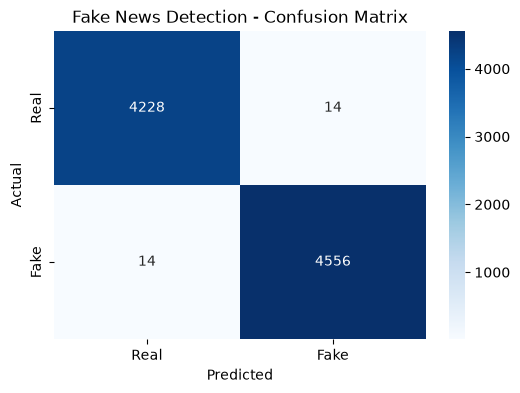

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Real", "Fake"],
    yticklabels=["Real", "Fake"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Fake News Detection - Confusion Matrix")
plt.show()

In [77]:
from sklearn.metrics import accuracy_score

y_train_pred = model.predict(X_train_tfidf)

train_accuracy = accuracy_score(y_train, y_train_pred)

print("Training Accuracy:", train_accuracy * 100, "%")

Training Accuracy: 100.0 %


In [78]:
print("Training Accuracy:", train_accuracy * 100, "%")
print("Testing Accuracy:", accuracy * 100, "%")

print("Accuracy Difference:", 
      (train_accuracy - accuracy) * 100, "%")

Training Accuracy: 100.0 %
Testing Accuracy: 99.68225147526101 %
Accuracy Difference: 0.3177485247389922 %


In [80]:
import joblib
import os

# Create a folder to store the trained model
os.makedirs("saved_models", exist_ok=True)

# Save the Random Forest model
joblib.dump(
    model,
    "saved_models/random_forest_model.pkl"
)

# Save the TF-IDF vectorizer
joblib.dump(
    tfidf,
    "saved_models/tfidf_vectorizer.pkl"
)

# Verify saved files
print("Model and vectorizer saved successfully!")

print("\nSaved files:")
print(os.listdir("saved_models"))

Model and vectorizer saved successfully!

Saved files:
['random_forest_model.pkl', 'tfidf_vectorizer.pkl']


In [81]:
print("Training label distribution:")
print(y_train.value_counts())

print("\nTraining label percentages:")
print(y_train.value_counts(normalize=True) * 100)

Training label distribution:
label
1    18278
0    16968
Name: count, dtype: int64

Training label percentages:
label
1    51.858367
0    48.141633
Name: proportion, dtype: float64


In [82]:
print("Predictions on test data:")
print(pd.Series(y_pred).value_counts())

print("\nPrediction percentages:")
print(pd.Series(y_pred).value_counts(normalize=True) * 100)

Predictions on test data:
1    4570
0    4242
Name: count, dtype: int64

Prediction percentages:
1    51.861099
0    48.138901
Name: proportion, dtype: float64


In [83]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["Real News", "Fake News"],
    digits=4
))

              precision    recall  f1-score   support

   Real News     0.9967    0.9967    0.9967      4242
   Fake News     0.9969    0.9969    0.9969      4570

    accuracy                         0.9968      8812
   macro avg     0.9968    0.9968    0.9968      8812
weighted avg     0.9968    0.9968    0.9968      8812



In [84]:
# Get one actual testing article
sample_news = X_test.iloc[0]

# Get its actual label
actual_label = y_test.iloc[0]

# Predict using the trained model
predicted_label = model.predict(
    tfidf.transform([sample_news])
)[0]

print("News Article:")
print(sample_news[:500])

print("\nActual Label:", actual_label)
print("Predicted Label:", predicted_label)

News Article:
 Marvel Vows To Boycott Georgia If Discriminatory Religious Liberty Bill Becomes Law The studio of superheroes will leave Georgia rather than make movies in a state that bullies gay people.The First Amendment Defense Act passed the Republican-dominated Georgia legislature earlier this month, but has yet to be signed by Governor Nathan Deal.Should the bill become law, it will allow conservative  Christians  to use their religion as a shield to justify bigotry and discrimination toward same-sex co

Actual Label: 1
Predicted Label: 1


In [85]:
# Training accuracy
train_accuracy = model.score(X_train_tfidf, y_train)

# Testing accuracy
test_accuracy = model.score(X_test_tfidf, y_test)

print("Training Accuracy:", train_accuracy * 100, "%")
print("Testing Accuracy:", test_accuracy * 100, "%")

Training Accuracy: 100.0 %
Testing Accuracy: 99.68225147526101 %


In [86]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Create Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train_tfidf, y_train)

# Predict test data
lr_predictions = lr_model.predict(X_test_tfidf)

# Calculate accuracy
lr_accuracy = accuracy_score(y_test, lr_predictions)

print("Logistic Regression Accuracy:", lr_accuracy * 100, "%")

# Show classification report
print(classification_report(y_test, lr_predictions))

Logistic Regression Accuracy: 99.21697684975034 %
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      4242
           1       1.00      0.99      0.99      4570

    accuracy                           0.99      8812
   macro avg       0.99      0.99      0.99      8812
weighted avg       0.99      0.99      0.99      8812



In [87]:
lr_train_accuracy = lr_model.score(X_train_tfidf, y_train)

lr_test_accuracy = lr_model.score(X_test_tfidf, y_test)

print("Logistic Regression Training Accuracy:",
      lr_train_accuracy * 100, "%")

print("Logistic Regression Testing Accuracy:",
      lr_test_accuracy * 100, "%")

Logistic Regression Training Accuracy: 99.47511774385745 %
Logistic Regression Testing Accuracy: 99.21697684975034 %


In [107]:
# Convert date column into proper datetime format

df["date_clean"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

# Check invalid dates
print("Invalid dates:", df["date_clean"].isna().sum())

# Check earliest date
print("Earliest date:", df["date_clean"].min())

# Check latest date
print("Latest date:", df["date_clean"].max())

Invalid dates: 30190
Earliest date: 2015-03-31 00:00:00
Latest date: 2017-12-31 00:00:00
